1. Image smoothing — basic concept
Image smoothing reduces noise and small intensity variations in an image. It works by replacing each pixel with a value calculated from its neighboring pixels.

For example, instead of keeping one pixel's intensity as 200, we might replace it with the average of the surrounding pixels.
The three filters









1. Averaging filter (unweighted)

All pixels in the filter window receive equal importance. For a \(3\times3\) filter, add the nine pixel values and divide by 9.












2. Weighted filter

Neighboring pixels receive different weights. Your assignment specifies \(h(x,y)=\max(|x|,|y|)\). We'll implement this formula exactly, while handling its zero-weight center separately.












3. Gaussian filter

Nearby pixels receive higher weights than distant pixels, following a Gaussian distribution. Sigma (\(\sigma\)) controls the spread of the weights.



Padding methods
- Zero padding: Pixels outside the image are treated as 0.
- Replication padding: The border pixel values are repeated beyond the image boundary.

Enter filter size (odd number): 3
Enter padding (zero / replication): zero
Enter Gaussian sigma (> 0): 1


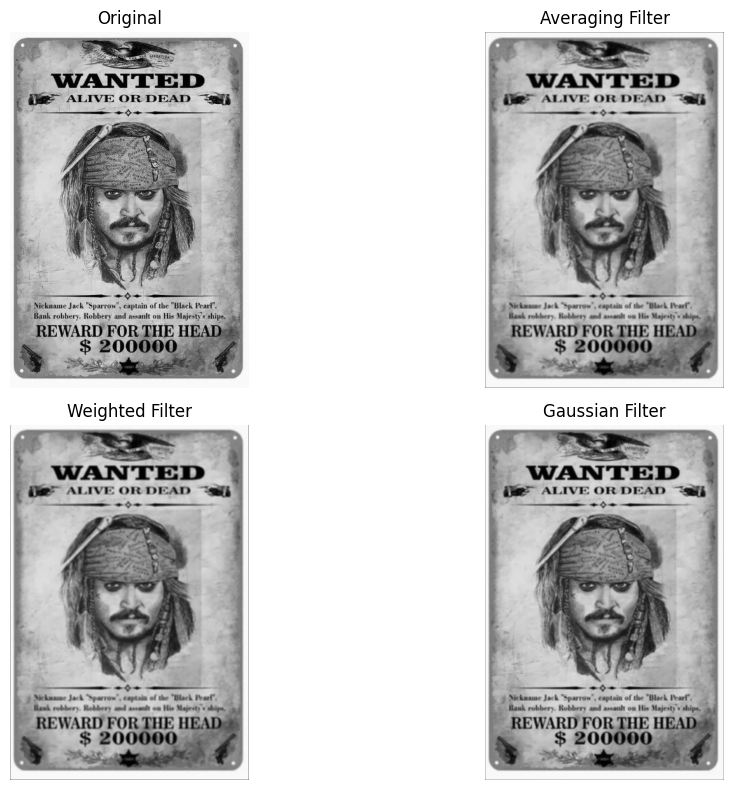

In [4]:
# Python code — without OpenCV

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Read grayscale image
img = np.array(
    Image.open("abc.jpg").convert("L"),
    dtype=np.float64
)

# Take input from user
size = int(input("Enter filter size (odd number): "))
padding_type = input(
    "Enter padding (zero / replication): "
).lower()

if size <= 0 or size % 2 == 0:
    raise ValueError("Filter size must be a positive odd number.")

if padding_type not in ("zero", "replication"):
    raise ValueError("Choose zero or replication padding.")

sigma = float(input("Enter Gaussian sigma (> 0): "))

if sigma <= 0:
    raise ValueError("Sigma must be greater than zero.")

# Create filter weights
r = size // 2
coords = np.arange(-r, r + 1)
X, Y = np.meshgrid(coords, coords)

# 1. Unweighted averaging filter
average_kernel = np.ones((size, size)) / (size * size)

# 2. Weighted filter: h(x,y) = max(|x|, |y|)
weighted_kernel = np.maximum(np.abs(X), np.abs(Y)).astype(float)

# Normalize weights; center has zero weight
weighted_kernel /= weighted_kernel.sum()

# 3. Gaussian filter
gaussian_kernel = np.exp(
    -(X**2 + Y**2) / (2 * sigma**2)
)
gaussian_kernel /= gaussian_kernel.sum()


def apply_filter(image, kernel, padding_type):
    r = kernel.shape[0] // 2

    if padding_type == "zero":
        padded = np.pad(
            image, ((r, r), (r, r)),
            mode="constant", constant_values=0
        )
    else:
        padded = np.pad(
            image, ((r, r), (r, r)),
            mode="edge"
        )

    output = np.zeros_like(image, dtype=float)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            region = padded[i:i + 2*r + 1,
                            j:j + 2*r + 1]

            output[i, j] = np.sum(region * kernel)

    return np.clip(output, 0, 255).astype(np.uint8)


# Apply all three filters
average_img = apply_filter(
    img, average_kernel, padding_type
)

weighted_img = apply_filter(
    img, weighted_kernel, padding_type
)

gaussian_img = apply_filter(
    img, gaussian_kernel, padding_type
)

# Display results
images = [
    (img, "Original"),
    (average_img, "Averaging Filter"),
    (weighted_img, "Weighted Filter"),
    (gaussian_img, "Gaussian Filter")
]

plt.figure(figsize=(12, 8))

for i, (image, title) in enumerate(images, 1):
    plt.subplot(2, 2, i)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

Enter filter size (odd number): 3
Enter padding (zero / replication): zero
Enter Gaussian sigma (> 0): 2


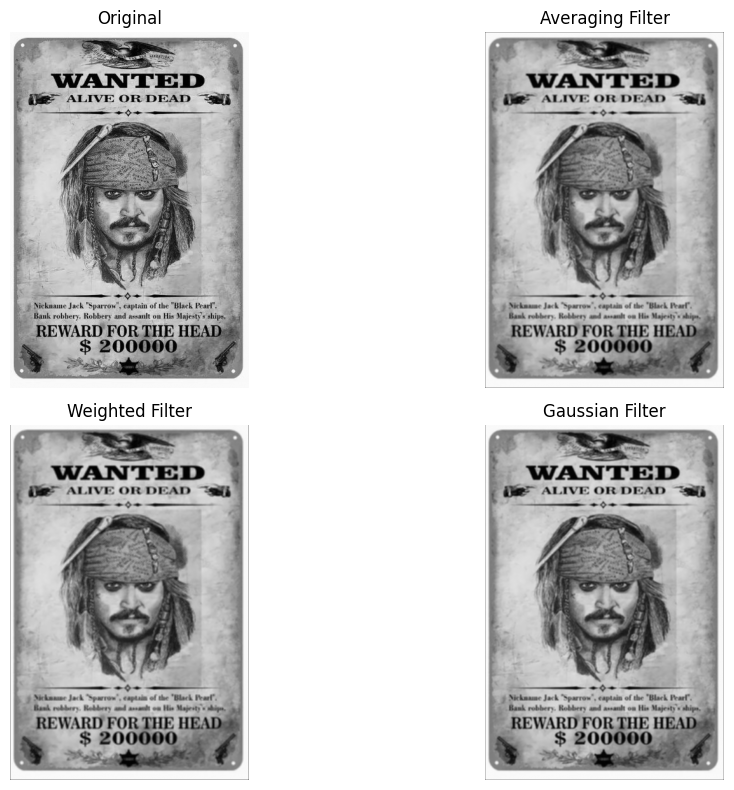

In [5]:
# OpenCV code

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("abc.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Check the image path.")

# User inputs
size = int(input("Enter filter size (odd number): "))
padding_type = input(
    "Enter padding (zero / replication): "
).lower()
sigma = float(input("Enter Gaussian sigma (> 0): "))

if size <= 0 or size % 2 == 0:
    raise ValueError("Filter size must be a positive odd number.")

if padding_type not in ("zero", "replication"):
    raise ValueError("Choose zero or replication padding.")

if sigma <= 0:
    raise ValueError("Sigma must be greater than zero.")

# Choose border handling
if padding_type == "zero":
    border_type = cv2.BORDER_CONSTANT
else:
    border_type = cv2.BORDER_REPLICATE

# 1. Averaging filter
average_img = cv2.blur(
    img, (size, size),
    borderType=border_type
)

# 2. Weighted filter: h(x,y) = max(|x|, |y|)
r = size // 2
coords = np.arange(-r, r + 1)
X, Y = np.meshgrid(coords, coords)

weighted_kernel = np.maximum(
    np.abs(X), np.abs(Y)
).astype(np.float32)

weighted_kernel /= weighted_kernel.sum()

weighted_img = cv2.filter2D(
    img, -1, weighted_kernel,
    borderType=border_type
)

# 3. Gaussian filter
gaussian_img = cv2.GaussianBlur(
    img, (size, size), sigmaX=sigma,
    borderType=border_type
)

# Display results
images = [
    (img, "Original"),
    (average_img, "Averaging Filter"),
    (weighted_img, "Weighted Filter"),
    (gaussian_img, "Gaussian Filter")
]

plt.figure(figsize=(12, 8))

for i, (image, title) in enumerate(images, 1):
    plt.subplot(2, 2, i)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()